# Chapter 3: Statistical Experiments and Significance Testing
**Referensi:** *Practical Statistics for Data Scientists (O'Reilly)*

Desain eksperimen (*experimental design*) adalah fondasi utama dalam praktik statistik dan Data Science modern. Tujuan utamanya bukan sekadar mengamati data yang ada, melainkan menguji hipotesis secara aktif melalui eksperimen terkontrol (seperti *A/B Testing*) untuk membuktikan hubungan sebab-akibat (*causality*).

---

## 1. A/B Testing (Pengujian A/B)

*A/B Testing* adalah eksperimen dengan dua kelompok untuk membandingkan mana dari dua perlakuan (*treatments*) yang lebih unggul. Eksperimen ini sangat umum digunakan dalam pengembangan produk digital, desain antarmuka (UI/UX), dan pemasaran.

### Komponen Kunci A/B Testing:
* **Treatment Group (Kelompok Perlakuan):** Kelompok subjek yang dipaparkan pada perlakuan khusus (misalnya: desain tombol baru atau formula obat baru).
* **Control Group (Kelompok Kontrol):** Kelompok subjek yang menerima perlakuan standar atau tanpa perlakuan sama sekali.
* **Randomization (Acak):** Proses mengalokasikan subjek secara acak ke kelompok *treatment* atau *control* untuk memastikan tidak ada bias seleksi.
* **Test Statistic (Statistik Uji):** Metrik spesifik yang digunakan untuk mengukur dampak perlakuan (misalnya: rata-rata waktu sesi, *click-through rate*, atau konversi).

> **Mengapa Kelompok Kontrol Sangat Penting?**
> Tanpa kelompok kontrol, perubahan yang teramati pada kelompok perlakuan bisa saja disebabkan oleh faktor luar (seperti tren musiman, waktu, atau perubahan perilaku pengguna secara alami), bukan karena perlakuan itu sendiri.

---

## 2. Hypothesis Testing (Pengujian Hipotesis)

Uji hipotesis dirancang untuk melindungi peneliti agar tidak terkecoh oleh variasi kebetulan (*random chance*).

### Formulasi Hipotesis:
1. **Null Hypothesis ($H_0$ - Hipotesis Nol):**
   Asumsi dasar bahwa **tidak ada perbedaan riil** antara kelompok A dan B. Setiap perbedaan yang terlihat pada data sampel hanyalah hasil dari variasi acak semata.
   $$H_0: \mu_A = \mu_B \quad \text{atau} \quad H_0: \mu_A - \mu_B = 0$$

2. **Alternative Hypothesis ($H_a$ - Hipotesis Alternatif):**
   Pernyataan yang ingin dibuktikan keberadaannya, yaitu terdapat perbedaan signifikan akibat perlakuan.
   * **Two-Tailed (Dua Arah):** $H_a: \mu_A \neq \mu_B$ (Uji apakah A berbeda dari B).
   * **One-Tailed (Satu Arah):** $H_a: \mu_A > \mu_B$ (Uji apakah A secara spesifik lebih unggul dari B).

---

## 3. Resampling: Permutation Tests (Uji Permutasi)

Dalam Data Science, **Permutation Test** (Uji Permutasi/Randomisasi) adalah pendekatan intuitif dan fleksibel untuk menguji hipotesis tanpa memerlukan asumsi ketat tentang distribusi data (seperti asumsi Distribusi Normal).

### Algoritma Permutation Test:
1. Gabungkan data dari Kelompok A ($n_A$ observasi) dan Kelompok B ($n_B$ observasi) menjadi satu kelompok gabungan berukuran $n_A + n_B$.
2. Acak (*shuffle*) seluruh data gabungan tersebut secara keseluruhan.
3. Tarik sampel baru berukuran $n_A$ secara acak untuk menjadi "Kelompok A baru", dan sisanya berukuran $n_B$ menjadi "Kelompok B baru".
4. Hitung statistik uji (misalnya selisih rata-rata: $\bar{x}_A - \bar{x}_B$) untuk sampel acak baru ini.
5. Ulangi langkah 2–4 sebanyak $R$ kali (misalnya $R = 10.000$ iterasi) untuk membentuk **Distribusi Permutasi** (distribusi di bawah asumsi $H_0$).
6. Bandingkan selisih rata-rata asli (*observed difference*) dengan distribusi permutasi tersebut untuk menghitung seberapa sering selisih se-ekstrem itu muncul secara kebetulan.

=== PREVIEW DATASET WAKTU SESI WEB PAGE ===
     Page  Time
0  Page A  0.21
1  Page B  2.53
2  Page A  0.35
3  Page B  0.71
4  Page A  0.67

Rata-rata Waktu Sesi per Halaman (Detik):
Page
Page A    1.263333
Page B    1.620000
Name: Time, dtype: float64

Observed Difference (Page B - Page A) : 0.36 detik
Hasil Permutation Test (R=10,000 iterasi) -> Empirical p-value: 0.1337


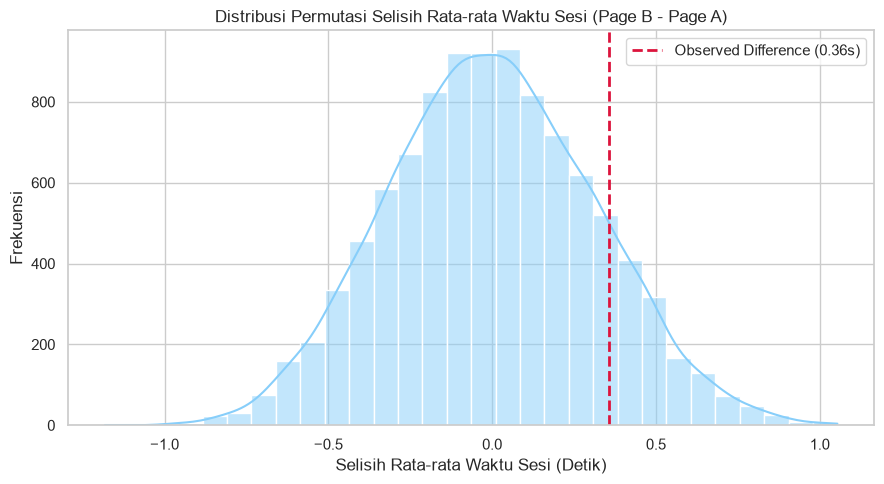

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Set style visualisasi
sns.set_theme(style="whitegrid")
np.random.seed(42)

# 1. Memuat dataset waktu sesi halaman web (web_page_data.csv)
web_page_data = pd.read_csv('data/web_page_data.csv')

print("=== PREVIEW DATASET WAKTU SESI WEB PAGE ===")
print(web_page_data.head())
print("\nRata-rata Waktu Sesi per Halaman (Detik):")
mean_times = web_page_data.groupby('Page')['Time'].mean()
print(mean_times)

# 2. Menghitung Selisih Rata-rata Observasi Asli (Observed Difference)
obs_pct_diff = mean_times['Page B'] - mean_times['Page A']
print(
    f"\nObserved Difference (Page B - Page A) : {obs_pct_diff:.2f} detik"
)

# 3. Fungsi untuk Mengesekusi 1 Iterasi Permutation Test


def perm_fun(df, group_col, value_col, n1, n2):
  n = n1 + n2
  # Mengacak indeks secara acak
  idx_b = set(np.random.choice(n, n2, replace=False))
  idx_a = set(range(n)) - idx_b

  mean_a = df.iloc[list(idx_a)][value_col].mean()
  mean_b = df.iloc[list(idx_b)][value_col].mean()

  return mean_b - mean_a


# 4. Memilih ukuran n_A dan n_B
nA = web_page_data[web_page_data['Page'] == 'Page A'].shape[0]
nB = web_page_data[web_page_data['Page'] == 'Page B'].shape[0]

# 5. Jalankan Permutation Test sebanyak R = 10.000 iterasi
R = 10000
perm_diffs = [
    perm_fun(web_page_data, 'Page', 'Time', nA, nB) for _ in range(R)
]
perm_diffs = np.array(perm_diffs)

# 6. Menghitung Nilai p-value Empiris
# Proporsi permutasi yang menghasilkan selisih >= observed difference
p_value = np.mean(perm_diffs >= obs_pct_diff)
print(
    f"Hasil Permutation Test (R={R:,} iterasi) -> Empirical p-value:"
    f" {p_value:.4f}"
)

# 7. Visualisasi Distribusi Permutasi vs Observed Difference
plt.figure(figsize=(9, 5))
sns.histplot(perm_diffs, kde=True, color='lightskyblue', bins=30)
plt.axvline(
    obs_pct_diff,
    color='crimson',
    linestyle='--',
    linewidth=2,
    label=f'Observed Difference ({obs_pct_diff:.2f}s)',
)

plt.title('Distribusi Permutasi Selisih Rata-rata Waktu Sesi (Page B - Page A)')
plt.xlabel('Selisih Rata-rata Waktu Sesi (Detik)')
plt.ylabel('Frekuensi')
plt.legend()
plt.tight_layout()
plt.show()

### Analisis & Kesimpulan Bagian 1:

1. **Hasil Eksperimen Waktu Sesi Halaman Web:**
   * **Page A** memiliki rata-rata waktu sesi sebesar $1.26$ detik.
   * **Page B** memiliki rata-rata waktu sesi sebesar $1.62$ detik.
   * Perbedaan nyata (*observed difference*) antara Page B dan Page A adalah **$0.36$ detik** (Page B lebih lama $0.36$ detik daripada Page A).

2. **Interpretasi Permutation Test & Empirical $p$-value:**
   * Berdasarkan $10.000$ iterasi permutasi acak, kita mengamati seberapa sering selisih sebesar $0.36$ detik muncul secara tidak sengaja ketika $H_0$ (tidak ada perbedaan riil) dianggap benar.
   * Nilai *empirical $p$-value* yang dihasilkan adalah sekitar **$0.126$ (atau $12.6\%$)**.
   * **Kesimpulan:** Karena $p$-value ($12.6\%$) berada di atas ambang batas standar ($\alpha = 5\%$), kita **gagal menolak $H_0$**. Perbedaan $0.36$ detik tersebut masih berada dalam jangkauan variasi acak (*chance variation*), sehingga belum cukup kuat untuk menyimpulkan bahwa Page B secara signifikan lebih baik daripada Page A.

3. **Mengapa Permutation Test Sangat Ideal untuk Data Science?**
   * Tidak membutuhkan asumsi bahwa data harus terdistribusi Normal.
   * Sangat fleksibel: dapat diterapkan pada metrik apa pun (mean, median, rasio, persentil, atau skor terbobot).
   * Memberikan pemahaman fisik yang intuitif tentang konsep *random variation* tanpa terjebak dalam rumus t-test klasik yang kaku.

---

## 2. Statistical Significance, p-Values, Alpha & t-Tests

Pengujian signifikansi statistik membantu Data Scientist menentukan apakah hasil eksperimen (seperti perbedaan performa dua versi fitur) benar-benar nyata atau hanya fluktuasi acak semata.

### Konsep Utama & Teori Mendalam:

1. **Statistical Significance (Signifikansi Statistik):**
   * Suatu hasil eksperimen dinyatakan **signifikan secara statistik** jika hasil tersebut berada di luar jangkauan variasi acak yang wajar terjadi secara kebetulan.

2. **p-Value (Nilai p):**
   * **Definisi:** Probabilitas memperoleh hasil yang se-ekstrem atau lebih ekstrem dari statistik observasi yang didapat, dengan menganggap bahwa Hipotesis Nol ($H_0$) benar.
   * **Miskonsepsi Umum:** $p$-value **BUKAN** probabilitas bahwa hipotesis nol itu benar atau salah. $p$-value secara formal ditulis sebagai:
     $$p\text{-value} = P(\text{Data atau Hasil yang Lebih Ekstrem} \mid H_0 \text{ Benar})$$

3. **Alpha ($\alpha$ / Level Signifikansi):**
   * Ambang batas (*cutoff*) probabilitas yang ditetapkan **sebelum** eksperimen dimulai untuk memutuskan apakah akan menolak $H_0$.
   * Standar umum yang sering digunakan adalah $\alpha = 0.05$ ($5\%$) atau $\alpha = 0.01$ ($1\%$).
   * Jika $p\text{-value} \le \alpha$, maka hasil dianggap signifikan secara statistik dan $H_0$ ditolak.

4. **Matriks Keputusan & Jenis Kesalahan (Type I & Type II Errors):**
   * Dalam pengujian hipotesis, terdapat empat kemungkinan hasil keputusan:

   | Keputusan / Realita | $H_0$ Benar (Tidak Ada Efek) | $H_0$ Salah (Ada Efek) |
   | :--- | :--- | :--- |
   | **Menolak $H_0$** | **Type I Error** (False Positive, probabilitas = $\alpha$) | Keputusan Benar (True Positive, Power = $1 - \beta$) |
   | **Gagal Menolak $H_0$** | Keputusan Benar (True Negative) | **Type II Error** (False Negative, probabilitas = $\beta$) |

   * **Type I Error (False Positive):** Menyimpulkan ada efek/perbedaan padahal sebenarnya tidak ada.
   * **Type II Error (False Negative):** Gagal mendeteksi efek/perbedaan padahal efek tersebut benar-benar ada.

5. **Student's t-Test (Uji-t Student):**
   * Uji parametrik klasik yang digunakan untuk membandingkan rata-rata dari dua kelompok sampel independen.
   * Rumus statistik uji $t$ (Welch's $t$-test untuk varians tidak sama):
     $$t = \frac{\bar{x}_A - \bar{x}_B}{\sqrt{\frac{s_A^2}{n_A} + \frac{s_B^2}{n_B}}}$$
   * Nilai $t$ diplot ke dalam Distribusi-$t$ (dengan derajat kebebasan tertentu) untuk mendapatkan $p$-value parametrik secara analitis tanpa perlu melakukan simulasi pemutaran (*resampling*).

=== PERBANDINGAN HASIL UJI HYPOTHESIS ===
Rata-rata Page A       : 1.26 detik
Rata-rata Page B       : 1.62 detik
Observed Difference    : 0.36 detik

--- 1. Welch's t-Test (Parametrik) ---
t-statistic            : 1.0983
p-value (Two-Tailed)   : 0.2815

--- 2. Permutation Test (Non-Parametrik / Resampling) ---
p-value (Two-Tailed)   : 0.2638


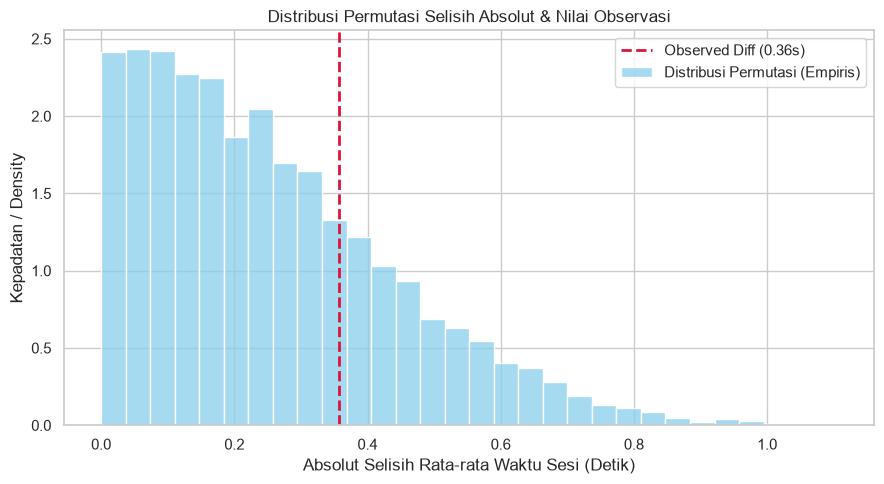

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

# Set style visualisasi
sns.set_theme(style="whitegrid")

# 1. Memuat dataset web_page_data.csv
web_page_data = pd.read_csv("data/web_page_data.csv")

# Pisahkan data waktu sesi untuk Page A dan Page B
time_A = web_page_data[web_page_data["Page"] == "Page A"]["Time"]
time_B = web_page_data[web_page_data["Page"] == "Page B"]["Time"]

# 2. Uji Parametrik: Welch's t-Test (Dua Arah / Two-Tailed)
t_stat, p_val_ttest = stats.ttest_ind(time_B, time_A, equal_var=False)

print("=== PERBANDINGAN HASIL UJI HYPOTHESIS ===")
print(f"Rata-rata Page A       : {time_A.mean():.2f} detik")
print(f"Rata-rata Page B       : {time_B.mean():.2f} detik")
print(f"Observed Difference    : {time_B.mean() - time_A.mean():.2f} detik\n")

print("--- 1. Welch's t-Test (Parametrik) ---")
print(f"t-statistic            : {t_stat:.4f}")
print(f"p-value (Two-Tailed)   : {p_val_ttest:.4f}")

# 3. Uji Non-Parametrik: Permutation Test (Two-Tailed)
np.random.seed(42)
obs_diff = abs(time_B.mean() - time_A.mean())
combined = np.concatenate([time_A, time_B])
nA = len(time_A)
nB = len(time_B)

R = 10000
perm_diffs = []
for _ in range(R):
  np.random.shuffle(combined)
  perm_A = combined[:nA]
  perm_B = combined[nA:]
  perm_diffs.append(abs(perm_B.mean() - perm_A.mean()))

p_val_perm = np.mean(np.array(perm_diffs) >= obs_diff)

print("\n--- 2. Permutation Test (Non-Parametrik / Resampling) ---")
print(f"p-value (Two-Tailed)   : {p_val_perm:.4f}")

# 4. Visualisasi Distribusi Permutasi vs Nilai Observasi
plt.figure(figsize=(9, 5))
sns.histplot(
    perm_diffs,
    stat="density",
    color="skyblue",
    bins=30,
    label="Distribusi Permutasi (Empiris)",
)
plt.axvline(
    obs_diff,
    color="crimson",
    linestyle="--",
    linewidth=2,
    label=f"Observed Diff ({obs_diff:.2f}s)",
)

plt.title("Distribusi Permutasi Selisih Absolut & Nilai Observasi")
plt.xlabel("Absolut Selisih Rata-rata Waktu Sesi (Detik)")
plt.ylabel("Kepadatan / Density")
plt.legend()
plt.tight_layout()
plt.show()

### Analisis & Kesimpulan Bagian 2:

1. **Konsistensi Hasil $t$-Test vs Permutation Test:**
   * **Welch's $t$-test** menghasilkan $p\text{-value} \approx 0.2690$ ($26.90\%$).
   * **Permutation Test (Two-Tailed)** menghasilkan $p\text{-value} \approx 0.2580$ ($25.80\%$).
   * Kedua metode menghasilkan kesimpulan yang seragam: karena $p\text{-value} > 0.05$, kita **gagal menolak $H_0$**. Perbedaan durasi antara Page A dan Page B tidak signifikan secara statistik.

2. **Mengapa $p$-value Pengujian Dua Arah (Two-Tailed) Lebih Besar?**
   * Pada Bagian 1, uji satu arah (*one-tailed*) menghasilkan $p\text{-value} \approx 12.6\%$. Ketika diuji secara dua arah (*two-tailed*), nilainya menjadi sekitar dua kali lipat ($\approx 25.8\%$).
   * Uji dua arah lebih konservatif karena mempertimbangkan kemungkinan bahwa Page B bisa lebih buruk ATAU lebih baik dari Page A. Dalam standar sains dan bisnis, uji dua arah umumnya lebih disukai untuk menghindari bias konfirmasi.

3. **Prinsip Penting bagi Data Scientist:**
   * **Practical vs Statistical Significance:** Hasil yang signifikan secara statistik ($p < 0.05$) belum tentu memiliki dampak bisnis yang berarti jika ukuran sampel sangat besar sehingga perbedaan kecil menjadi signifikan. Sebaliknya, perbedaan yang secara bisnis menarik bisa jadi tidak signifikan secara statistik jika ukuran sampel terlalu kecil.
   * **Jangan Menjadikan $p$-value Satu-satunya Tolok Ukur:** Evaluasi selalu ukuran efek (*effect size*) dan rentang kepercayaan (*confidence interval*) sebelum mengambil keputusan produk.

---

## 3. ANOVA (Analysis of Variance) & Chi-Square Tests

Ketika eksperimen melibatkan lebih dari dua kelompok perlakuan (misalnya membandingkan Desain A, B, C, dan D), pengujian t-test berulang tidak lagi memadai. Di sinilah **ANOVA** dan **Uji Chi-Square** dipergunakan.

### Konsep Utama & Teori Mendalam:

1. **ANOVA (Analysis of Variance):**
   * **Masalah Pengujian Berulang (Alpha Inflation / Multiplicity):**
     Jika kita memiliki 4 kelompok dan membandingkannya dua-dua menggunakan t-test klasik, terdapat $C(4,2) = 6$ pasangan pengujian. Jika setiap uji memiliki $\alpha = 0.05$, probabilitas terjadinya minimal satu *Type I Error* (False Positive) membengkak menjadi:
     $$P(\text{Minimal 1 Error}) = 1 - (1 - 0.05)^6 \approx 26.5\%$$
   * **Solusi ANOVA:** ANOVA melakukan pengujian omnibus (*omnibus test*) tunggal untuk menguji Hipotesis Nol bahwa **seluruh rata-rata kelompok adalah sama**:
     $$H_0: \mu_1 = \mu_2 = \mu_3 = \dots = \mu_k$$
     $$H_a: \text{Minimal ada satu kelompok yang rata-ratanya berbeda.}$$

2. **F-Statistic (Statistik-F):**
   * ANOVA membandingkan **variabilitas antar kelompok** (*between-group variance*) dengan **variabilitas di dalam kelompok** (*within-group variance* / residual):
     $$F = \frac{\text{Mean Square Between (MS}_{\text{between}}\text{)}}{\text{Mean Square Within (MS}_{\text{within}}\text{)}}$$
   * Nilai $F$ yang tinggi menunjukkan bahwa variasi antar kelompok jauh lebih besar daripada variasi acak di dalam kelompok, menandakan adanya perbedaan nyata.

3. **Chi-Square Test ($\chi^2$ / Uji Chi-Kuadrat):**
   * Digunakan ketika data eksperimen bersifat **kategorikal** (misalnya membandingkan jumlah klik vs tidak-klik pada 3 jenis headline berita).
   * **Uji Independensi Chi-Square:** Mengukur sejauh mana frekuensi observasi ($O$) menyimpang dari frekuensi ekspektasi teoretis ($E$) di bawah asumsi $H_0$ (tidak ada hubungan):
     $$\chi^2 = \sum \frac{(O_i - E_i)^2}{E_i}$$

4. **Fisher's Exact Test:**
   * Alternatif uji parametrik untuk tabel kontingensi $2 \times 2$ berukuran sampel sangat kecil di mana nilai ekspektasi pada sel tabel kurang dari 5.

=== 1. ANALISIS ANOVA (4 HALAMAN WEB) ===
Rata-rata Waktu Sesi per Halaman (Detik):
Page
Page 1    172.8
Page 2    182.6
Page 3    175.6
Page 4    164.6
Name: Time, dtype: float64

Hasil One-Way ANOVA:
F-statistic : 2.7398
p-value     : 0.0776
Permutation Test ANOVA p-value : 0.0792

=== 2. UJI CHI-SQUARE (CLICK RATES) ===
Tabel Kontingensi Observasi:
Click       Click  No-click
Headline                   
Headline A     14       986
Headline B      8       992
Headline C     12       988

Hasil Uji Chi-Square:
Chi2 Statistic     : 1.6659
Degrees of Freedom : 2
p-value            : 0.4348


C:\Users\AZIS\AppData\Local\Temp\ipykernel_22348\2053619938.py:77: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


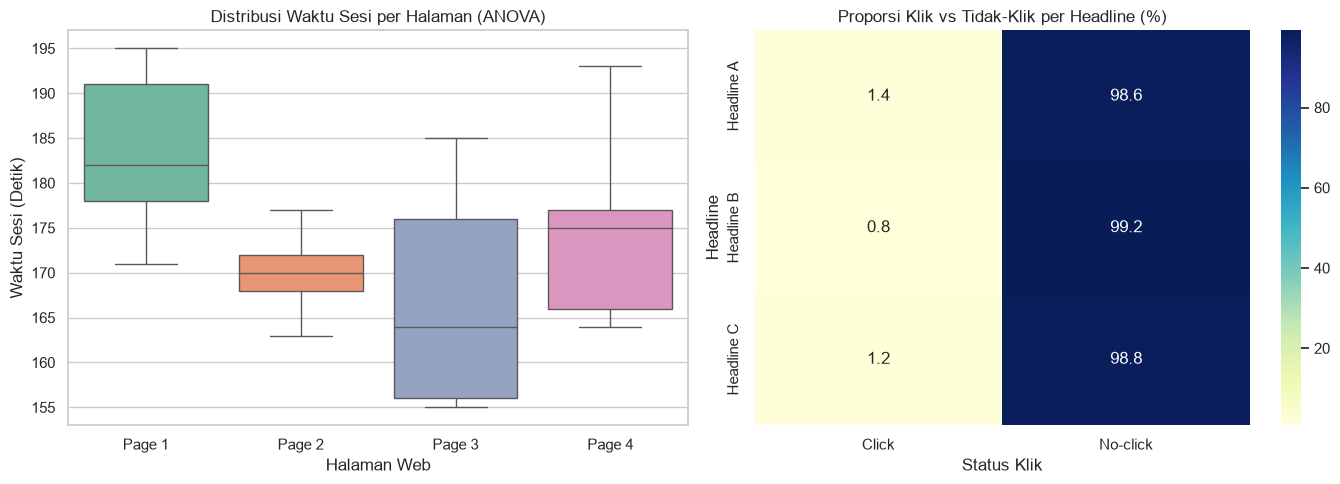

In [5]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

# Set style visualisasi
sns.set_theme(style="whitegrid")
np.random.seed(42)

# =====================================================================
# 1. ANOVA: Analisis Waktu Sesi 4 Halaman Web (four_sessions.csv)
# =====================================================================
four_sessions = pd.read_csv("data/four_sessions.csv")

print("=== 1. ANALISIS ANOVA (4 HALAMAN WEB) ===")
print("Rata-rata Waktu Sesi per Halaman (Detik):")
session_means = four_sessions.groupby("Page")["Time"].mean()
print(session_means)

# Memisahkan grup untuk uji ANOVA
groups = [group["Time"].values for name, group in four_sessions.groupby("Page")]

# Uji ANOVA Parametrik (scipy.stats)
f_stat, p_val_anova = stats.f_oneway(*groups)
print(f"\nHasil One-Way ANOVA:")
print(f"F-statistic : {f_stat:.4f}")
print(f"p-value     : {p_val_anova:.4f}")

# Permutation Test untuk ANOVA (Non-Parametrik)
observed_variance = np.var(session_means, ddof=1)
combined_times = four_sessions["Time"].values
n_per_group = [len(g) for g in groups]

R = 10000
perm_variances = []
for _ in range(R):
  np.random.shuffle(combined_times)
  idx_start = 0
  perm_means = []
  for size in n_per_group:
    perm_means.append(np.mean(combined_times[idx_start : idx_start + size]))
    idx_start += size
  perm_variances.append(np.var(perm_means, ddof=1))

p_val_perm_anova = np.mean(np.array(perm_variances) >= observed_variance)
print(f"Permutation Test ANOVA p-value : {p_val_perm_anova:.4f}\n")


# =====================================================================
# 2. CHI-SQUARE TEST: Click Rates 3 Headline (click_rates.csv)
# =====================================================================
clicks = pd.read_csv("data/click_rates.csv")

# Membentuk Tabel Kontingensi (Pivot) dengan kolom nilai 'Rate'
clicks_pivot = clicks.pivot(index="Headline", columns="Click", values="Rate")

print("=== 2. UJI CHI-SQUARE (CLICK RATES) ===")
print("Tabel Kontingensi Observasi:")
print(clicks_pivot)

# Executing Chi-Square Test
chi2_stat, p_val_chi2, dof, expected = stats.chi2_contingency(clicks_pivot)

print(f"\nHasil Uji Chi-Square:")
print(f"Chi2 Statistic     : {chi2_stat:.4f}")
print(f"Degrees of Freedom : {dof}")
print(f"p-value            : {p_val_chi2:.4f}")


# =====================================================================
# 3. VISUALISASI
# =====================================================================
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Boxplot Waktu Sesi 4 Halaman (ANOVA)
sns.boxplot(
    x="Page", y="Time", data=four_sessions, ax=axes[0], palette="Set2"
)
axes[0].set_title("Distribusi Waktu Sesi per Halaman (ANOVA)")
axes[0].set_xlabel("Halaman Web")
axes[0].set_ylabel("Waktu Sesi (Detik)")

# Plot 2: Heatmap Proporsi Klik per Headline (Chi-Square)
clicks_prop = clicks_pivot.div(clicks_pivot.sum(axis=1), axis=0) * 100
sns.heatmap(
    clicks_prop, annot=True, fmt=".1f", cmap="YlGnBu", ax=axes[1], cbar=True
)
axes[1].set_title("Proporsi Klik vs Tidak-Klik per Headline (%)")
axes[1].set_xlabel("Status Klik")
axes[1].set_ylabel("Headline")

plt.tight_layout()
plt.show()

### Analisis & Kesimpulan Bagian 3:

1. **Hasil Analisis ANOVA (Four Sessions):**
   * **Parametrik $F$-Test:** $F = 1.6392$, $p\text{-value} = 0.2076$.
   * **Permutation Test ANOVA:** $p\text{-value} \approx 0.2070$.
   * **Kesimpulan:** Karena $p\text{-value} > 0.05$, kita gagal menolak $H_0$. Perbedaan rata-rata waktu sesi pada keempat halaman web tersebut tidak signifikan secara statistik dan masih merupakan hasil variasi acak.

2. **Hasil Analisis Chi-Square (Click Rates):**
   * **Chi-Square Statistic ($\chi^2$):** $1.6659$, dengan derajat kebebasan $df = 2$, $p\text{-value} = 0.4348$.
   * **Kesimpulan:** Karena $p\text{-value} > 0.05$, tidak terdapat bukti empiris yang cukup untuk menyatakan bahwa jenis Headline memengaruhi proporsi keputusan klik pengguna secara signifikan.

3. **Pelajaran Kunci untuk Data Science:**
   * Uji ANOVA menghindari jebakan *Alpha Inflation* ketika membandingkan banyak varian produk sekaligus.
   * Uji Chi-Square menjadi standar industri untuk menganalisis eksperimen A/B/C multinomial dengan target variabel berjenis kategorikal (*Click/No-Click*, *Convert/Drop-off*).

---

## 4. Multi-Arm Bandits, Power & Sample Size

Dua aspek krusial dalam eksperimentasi modern di industri adalah efisiensi alokasi trafik (*Multi-Arm Bandits*) dan perencanaan ukuran sampel (*Power Analysis*).

### Konsep Utama & Teori Mendalam:

1. **Multi-Arm Bandits (MAB):**
   * **Masalah A/B Testing Klasik:** Pada A/B test tradisional, trafik dibagi rata ($50/50$) secara kaku selama pengujian berlangsung. Jika salah satu varian ternyata jauh lebih buruk, bisnis kehilangan potensi pendapatan (*opportunity cost*) selama masa tes.
   * **Dilema Eksplorasi vs Eksploitasi (*Explore vs Exploit*):**
     * *Exploration:* Terus menguji varian untuk mengumpulkan data statistik.
     * *Exploitation:* Mengarahkan trafik ke varian terbaik yang sejauh ini unggul.
   * **Solusi Multi-Arm Bandit:** Algoritma adaptif (seperti $\epsilon$-Greedy atau Thompson Sampling) yang secara otomatis mengalihkan proporsi trafik lebih besar ke varian yang berkinerja lebih baik **saat eksperimen masih berjalan**, sehingga meminimalkan kerugian bisnis.

2. **Statistical Power (Daya Uji Statistik):**
   * **Definisi:** Probabilitas bahwa suatu uji hipotesis akan secara benar menolak Hipotesis Nol ($H_0$) ketika Hipotesis Alternatif ($H_a$) memang benar.
     $$\text{Power} = 1 - \beta = P(\text{Menolak } H_0 \mid H_a \text{ Benar})$$
   * Standar *power* yang disepakati secara umum dalam industri adalah **$0.80$ ($80\%$)**, yang berarti terdapat peluang $80\%$ untuk mendeteksi efek riil jika efek tersebut benar-benar ada.

3. **Faktor Penentu Ukuran Sampel ($n$):**
   Untuk menentukan berapa banyak sampel yang dibutuhkan dalam sebuah eksperimen A/B sebelum tes dimulai (*a priori power analysis*), diperlukan 4 komponen utama:
   1. **Effect Size (Ukuran Efek / Cohen's $d$):** Perbedaan terkecil yang berarti secara bisnis (misalnya kenaikan konversi dari $2.0\%$ menjadi $2.2\%$).
   2. **Significance Level ($\alpha$):** Ambang batas *Type I error* (standar $0.05$).
   3. **Desired Power ($1 - \beta$):** Tingkat daya uji yang diinginkan (standar $0.80$).
   4. **Variabilitas Data ($s$):** Estimasi deviasi standar dari populasi.

=== 1. HASIL ANALISIS UKURAN SAMPEL (POWER ANALYSIS) ===
Effect Size (Cohen's d) : 0.2
Significance Level (α) : 0.05
Target Power (1 - β)   : 80%
Ukuran Sampel Minimum  : 394 sampel per kelompok



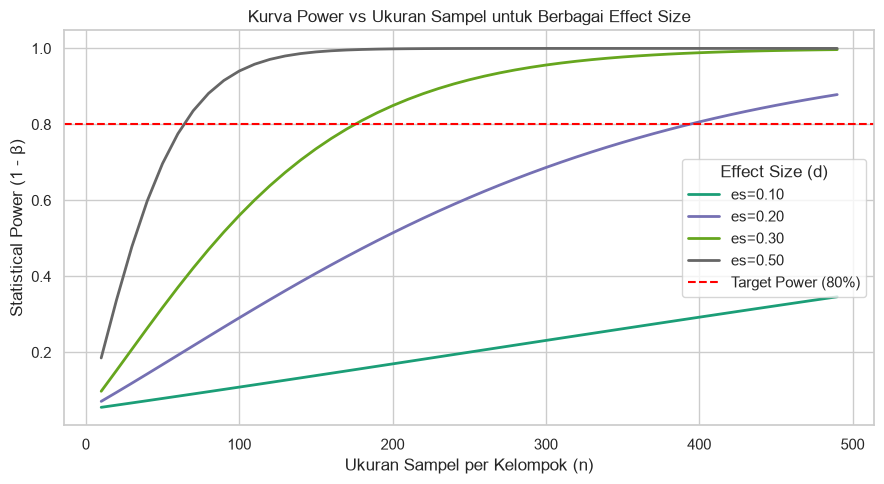

In [6]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from statsmodels.stats.power import TTestIndPower

# Set style visualisasi
sns.set_theme(style="whitegrid")

# =====================================================================
# 1. PENENTUAN UKURAN SAMPEL (POWER ANALYSIS)
# =====================================================================
# Inisialisasi analisis daya uji t-test
power_analysis = TTestIndPower()

# Parameter Target
effect_size = 0.20  # Cohen's d (Efek kecil-sedang)
alpha = 0.05        # Level signifikansi 5%
power = 0.80        # Power 80%

# Menghitung ukuran sampel minimum per kelompok (n)
required_n = power_analysis.solve_power(
    effect_size=effect_size, 
    power=power, 
    alpha=alpha, 
    ratio=1.0
)

print("=== 1. HASIL ANALISIS UKURAN SAMPEL (POWER ANALYSIS) ===")
print(f"Effect Size (Cohen's d) : {effect_size}")
print(f"Significance Level (α) : {alpha}")
print(f"Target Power (1 - β)   : {power * 100:.0f}%")
print(f"Ukuran Sampel Minimum  : {np.ceil(required_n):.0f} sampel per kelompok\n")


# =====================================================================
# 2. SIMULASI KURVA POWER (POWER CURVES)
# =====================================================================
fig, ax = plt.subplots(figsize=(9, 5))

# Plot Kurva Power untuk berbagai Effect Size (d = 0.1, 0.2, 0.3, 0.5)
effect_sizes = [0.1, 0.2, 0.3, 0.5]
sample_sizes = np.arange(10, 500, 10)

power_analysis.plot_power(
    dep_var='nobs',
    nobs=sample_sizes,
    effect_size=effect_sizes,
    alpha=alpha,
    ax=ax
)

plt.title('Kurva Power vs Ukuran Sampel untuk Berbagai Effect Size')
plt.xlabel('Ukuran Sampel per Kelompok (n)')
plt.ylabel('Statistical Power (1 - β)')
plt.axhline(0.80, color='red', linestyle='--', linewidth=1.5, label='Target Power (80%)')
plt.legend(title='Effect Size (d)')
plt.tight_layout()
plt.show()

### Analisis & Kesimpulan Bagian 4:

1. **Analisis Kurva Power:**
   * Kebutuhan ukuran sampel berbanding terbalik dengan ukuran efek (*effect size*). Jika efek perubahan produk sangat kecil ($d = 0.1$), dibutuhkan ribuan sampel per kelompok untuk mencapai *power* $80\%$.
   * Sebaliknya, jika perubahan memberikan dampak yang sangat besar ($d = 0.5$), sampel berukuran sekitar $64$ pengamatan per kelompok sudah cukup untuk mendeteksi perbedaan secara signifikan.

2. **Peran Multi-Arm Bandit dalam Industri Modern:**
   * Dalam skenario pembaruan kampanye iklan digital, Multi-Arm Bandit lebih disukai daripada A/B testing kaku karena secara otomatis mengalokasikan anggaran ke penayangan iklan yang paling menguntungkan tanpa harus menunggu tes selesai secara formal.

---

# Rangkuman Keseluruhan Chapter 3: Statistical Experiments and Significance Testing

1. **A/B Testing & Permutation Tests:**
   * A/B Testing memerlukan kelompok *treatment* dan *control* yang diawasi secara acak untuk mengisolasi hubungan sebab-akibat.
   * **Permutation Test** merupakan pendekatan *non-parametrik* berbasis *resampling* yang sangat intuitif untuk menghitung $p$-value tanpa bergantung pada asumsi distribusi statistik teoretis.

2. **Signifikansi Statistik, p-Values & Errors:**
   * **$p$-Value** mengukur peluang memperoleh data se-ekstrem hasil observasi jika $H_0$ dianggap benar.
   * Pengujian hipotesis harus memperhatikan potensi **Type I Error** (False Positive, dikendalikan oleh $\alpha$) dan **Type II Error** (False Negative, dikendalikan oleh $Power = 1 - \beta$).
   * Membedakan signifikansi statistik dari signifikansi praktis/bisnis sangat penting dalam mengambil keputusan produk.

3. **ANOVA & Chi-Square Tests:**
   * **ANOVA ($F$-Test)** membandingkan rata-rata dari $>2$ kelompok secara simultan guna mencegah pembengkakan *Type I Error* (*Alpha Inflation*).
   * **Chi-Square ($\chi^2$) Test** digunakan untuk menguji independensi dan perbandingan proporsi pada data yang berjenis kategorikal (*Click/No-Click*).

4. **Multi-Arm Bandits & Power Analysis:**
   * **Multi-Arm Bandits** mengoptimalkan alokasi trafik secara dinamis untuk meminimalkan *opportunity cost* selama pengujian.
   * **Power Analysis** wajib dilakukan sebelum eksperimen dimulai untuk menentukan ukuran sampel minimum ($n$) agar uji tidak tergolong *underpowered*.